## Install library DGL
### Desinstalar torch 
pip uninstall torch torchvision torchaudio -y
###  Instalar la version correcta
pip install torch==2.4.0 torchvision==0.19.0 torchaudio==2.4.0 \
--index-url https://download.pytorch.org/whl/cu118
### Instalar dgl
pip install dgl -f https://data.dgl.ai/wheels/torch-2.4/cu118/repo.html


In [5]:
import os
os.environ["DGLBACKEND"] = "pytorch"

In [89]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from dgl.nn.pytorch import GATConv
# Graficas
import networkx as nx
import matplotlib.pyplot as plt

In [8]:
class GATLayer(nn.Module):
    def __init__(self, g, in_dim, out_dim):
        super(GATLayer, self).__init__()
        self.g = g
        # equation (1)
        self.fc = nn.Linear(in_dim, out_dim, bias=False)
        # equation (2)
        self.attn_fc = nn.Linear(2 * out_dim, 1, bias=False)
        self.reset_parameters()

    def reset_parameters(self):
        """Reinitialize learnable parameters."""
        gain = nn.init.calculate_gain("relu")
        nn.init.xavier_normal_(self.fc.weight, gain=gain)
        nn.init.xavier_normal_(self.attn_fc.weight, gain=gain)

    def edge_attention(self, edges):
        # edge UDF for equation (2)
        z2 = torch.cat([edges.src["z"], edges.dst["z"]], dim=1)
        a = self.attn_fc(z2)
        return {"e": F.leaky_relu(a)}

    def message_func(self, edges):
        # message UDF for equation (3) & (4)
        return {"z": edges.src["z"], "e": edges.data["e"]}

    def reduce_func(self, nodes):
        # reduce UDF for equation (3) & (4)
        # equation (3)
        alpha = F.softmax(nodes.mailbox["e"], dim=1)
        # equation (4)
        h = torch.sum(alpha * nodes.mailbox["z"], dim=1)
        return {"h": h}

    def forward(self, h):
        # equation (1)
        z = self.fc(h)
        self.g.ndata["z"] = z
        # equation (2)
        self.g.apply_edges(self.edge_attention)
        # equation (3) & (4)
        self.g.update_all(self.message_func, self.reduce_func)
        return self.g.ndata.pop("h")

In [9]:
class MultiHeadGATLayer(nn.Module):
    def __init__(self, g, in_dim, out_dim, num_heads, merge="cat"):
        super(MultiHeadGATLayer, self).__init__()
        self.heads = nn.ModuleList()
        for i in range(num_heads):
            self.heads.append(GATLayer(g, in_dim, out_dim))
        self.merge = merge

    def forward(self, h):
        head_outs = [attn_head(h) for attn_head in self.heads]
        if self.merge == "cat":
            # concat on the output feature dimension (dim=1)
            return torch.cat(head_outs, dim=1)
        else:
            # merge using average
            return torch.mean(torch.stack(head_outs))

In [10]:
class GAT(nn.Module):
    def __init__(self, g, in_dim, hidden_dim, out_dim, num_heads):
        super(GAT, self).__init__()
        self.layer1 = MultiHeadGATLayer(g, in_dim, hidden_dim, num_heads)
        # Be aware that the input dimension is hidden_dim*num_heads since
        # multiple head outputs are concatenated together. Also, only
        # one attention head in the output layer.
        self.layer2 = MultiHeadGATLayer(g, hidden_dim * num_heads, out_dim, 1)

    def forward(self, h):
        h = self.layer1(h)
        h = F.elu(h)
        h = self.layer2(h)
        return h


import networkx as nx

In [75]:
from dgl import DGLGraph
from dgl.data import citation_graph as citegrh


def load_cora_data():
    data = citegrh.load_cora()
    g = data[0]
    mask = torch.BoolTensor(g.ndata["train_mask"])
    return g, g.ndata["feat"], g.ndata["label"], mask

In [83]:
data = citegrh.load_cora()

print("DATASET")
print(data)

print("\nGRAPH")
g = data[0]
print(g)

print("\nNUMBER OF NODES")
print(g.num_nodes())

print("\nNUMBER OF EDGES")
print(g.num_edges())

print("\nNODE DATA")
print(g.ndata)

print("\nEDGE DATA")
print(g.edata)

print("\nFEATURES")
print(g.ndata['feat'].shape)

print("\nLABELS")
print(g.ndata['label'].shape)

print("\nTRAIN MASK")
print(g.ndata['train_mask'].shape)

print("\nVALIDATION MASK")
print(g.ndata['val_mask'].shape)

print("\nTEST MASK")
print(g.ndata['test_mask'].shape)

print("\nNUMBER OF CLASSES")
print(data.num_classes)

  NumNodes: 2708
  NumEdges: 10556
  NumFeats: 1433
  NumClasses: 7
  NumTrainingSamples: 140
  NumValidationSamples: 500
  NumTestSamples: 1000
Done loading data from cached files.
DATASET
Dataset("cora_v2", num_graphs=1, save_path=/home/usuario/.dgl/cora_v2_d697a464)

GRAPH
Graph(num_nodes=2708, num_edges=10556,
      ndata_schemes={'feat': Scheme(shape=(1433,), dtype=torch.float32), 'label': Scheme(shape=(), dtype=torch.int64), 'test_mask': Scheme(shape=(), dtype=torch.bool), 'val_mask': Scheme(shape=(), dtype=torch.bool), 'train_mask': Scheme(shape=(), dtype=torch.bool)}
      edata_schemes={})

NUMBER OF NODES
2708

NUMBER OF EDGES
10556

NODE DATA
{'feat': tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]), 'label': tensor([3, 4, 4,  ..., 3, 3, 3]), 'test_mask': tensor([False, Fal

In [88]:
node = 0

print("FEATURES:")
print(g.ndata['feat'][node])

print("LABEL:")
print(g.ndata['label'][node])

print("TRAIN:")
print(g.ndata['train_mask'][node])

print("VALIDATION:")
print(g.ndata['val_mask'][node])

print("TEST:")
print(g.ndata['test_mask'][node])

FEATURES:
tensor([0., 0., 0.,  ..., 0., 0., 0.])
LABEL:
tensor(3)
TRAIN:
tensor(True)
VALIDATION:
tensor(False)
TEST:
tensor(False)


In [107]:
src, dst = g.edges()

print(src[6:11])
print(dst[6:11])

tensor([2, 2, 2, 2, 2])
tensor([   1, 1986,  332, 1666, 1454])


In [105]:
neighbors = g.successors(2) 
print(neighbors)
# nx_g = g.to_networkx()
# node_colors = []

# for node in nx_g.nodes():
#     if node in neighbors.tolist():
#         node_colors.append('red')
#     else:
#         node_colors.append('lightblue')

# nx.draw(nx_g, with_labels=True, node_color=node_colors)
# plt.show()

tensor([   1, 1986,  332, 1666, 1454])


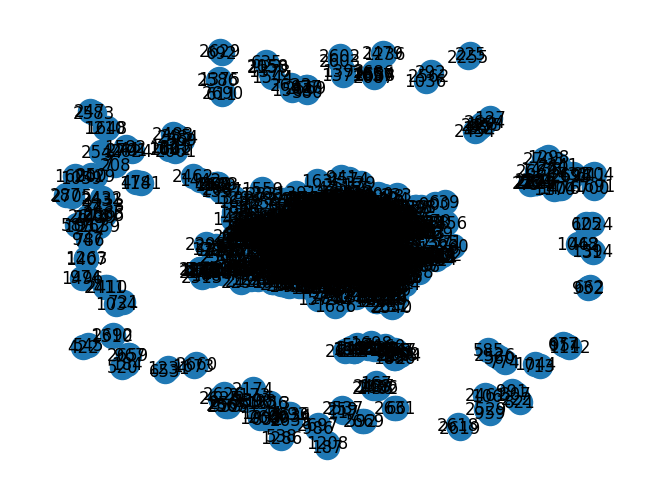

In [91]:
# convierte de DGL graph → NetworkX graph
nx_g = g.to_networkx()

nx.draw(nx_g, with_labels=True)
plt.show()

In [108]:
import time

import numpy as np

g, features, labels, mask = load_cora_data()

# create the model, 2 heads, each head has hidden size 8
net = GAT(g, in_dim=features.size()[1], hidden_dim=8, out_dim=7, num_heads=2)

# create optimizer
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

# main loop
dur = []
for epoch in range(30):
    if epoch >= 3:
        t0 = time.time()

    logits = net(features)
    logp = F.log_softmax(logits, 1)
    loss = F.nll_loss(logp[mask], labels[mask])

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if epoch >= 3:
        dur.append(time.time() - t0)

    print(
        "Epoch {:05d} | Loss {:.4f} | Time(s) {:.4f}".format(
            epoch, loss.item(), np.mean(dur)
        )
    )

  NumNodes: 2708
  NumEdges: 10556
  NumFeats: 1433
  NumClasses: 7
  NumTrainingSamples: 140
  NumValidationSamples: 500
  NumTestSamples: 1000
Done loading data from cached files.
Epoch 00000 | Loss 1.9455 | Time(s) nan
Epoch 00001 | Loss 1.9436 | Time(s) nan


/home/usuario/prg/anaconda3/envs/dgl-env/lib/python3.9/site-packages/numpy/_core/fromnumeric.py:3596: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/usuario/prg/anaconda3/envs/dgl-env/lib/python3.9/site-packages/numpy/_core/_methods.py:138: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Epoch 00002 | Loss 1.9416 | Time(s) nan
Epoch 00003 | Loss 1.9396 | Time(s) 0.0710
Epoch 00004 | Loss 1.9377 | Time(s) 0.0699
Epoch 00005 | Loss 1.9357 | Time(s) 0.0704
Epoch 00006 | Loss 1.9337 | Time(s) 0.0782
Epoch 00007 | Loss 1.9318 | Time(s) 0.0785
Epoch 00008 | Loss 1.9298 | Time(s) 0.0769
Epoch 00009 | Loss 1.9278 | Time(s) 0.0767
Epoch 00010 | Loss 1.9258 | Time(s) 0.0770
Epoch 00011 | Loss 1.9238 | Time(s) 0.0795
Epoch 00012 | Loss 1.9218 | Time(s) 0.0788
Epoch 00013 | Loss 1.9198 | Time(s) 0.0789
Epoch 00014 | Loss 1.9178 | Time(s) 0.0792
Epoch 00015 | Loss 1.9158 | Time(s) 0.0781
Epoch 00016 | Loss 1.9137 | Time(s) 0.0780
Epoch 00017 | Loss 1.9117 | Time(s) 0.0778
Epoch 00018 | Loss 1.9096 | Time(s) 0.0780
Epoch 00019 | Loss 1.9076 | Time(s) 0.0776
Epoch 00020 | Loss 1.9055 | Time(s) 0.0817
Epoch 00021 | Loss 1.9034 | Time(s) 0.0820
Epoch 00022 | Loss 1.9013 | Time(s) 0.0830
Epoch 00023 | Loss 1.8992 | Time(s) 0.0828
Epoch 00024 | Loss 1.8971 | Time(s) 0.0827
Epoch 00025 | 

# 2. Crear Grafos con DGL

In [17]:
import dgl
import torch as th

# edges 0->1, 0->2, 0->3, 1->3
u, v = th.tensor([0, 0, 0, 1]), th.tensor([1, 2, 3, 3])
g = dgl.graph((u, v))
print("Graph: ", g) # number of nodes are inferred from the max node IDs in the given edges

# Node IDs
print("Nodes:", g.nodes())
# Edge end nodes
print("Edges: ",g.edges())
# Edge end nodes and edge IDs
print("Edges and Nodes: ",g.edges(form='all'))

# If the node with the largest ID is isolated (meaning no edges),
# then one needs to explicitly set the number of nodes
g = dgl.graph((u, v), num_nodes=8)

Graph:  Graph(num_nodes=4, num_edges=4,
      ndata_schemes={}
      edata_schemes={})
Nodes: tensor([0, 1, 2, 3])
Edges:  (tensor([0, 0, 0, 1]), tensor([1, 2, 3, 3]))
Edges and Nodes:  (tensor([0, 0, 0, 1]), tensor([1, 2, 3, 3]), tensor([0, 1, 2, 3]))


In [21]:
#Grafos Bidireccionales

bg = dgl.to_bidirected(g)
bg.edges()

(tensor([0, 0, 0, 1, 1, 2, 3, 3]), tensor([1, 2, 3, 0, 3, 0, 0, 1]))

In [51]:
# Node and Edge Features
g = dgl.graph(([0, 0, 1, 5], [1, 2, 2, 0])) # 6 nodes, 4 edges
print("1. Graph: ",g)
print("1. Nodes: ",g.num_nodes())
print("1. Edges: ",g.num_edges())
print(th.ones(g.num_nodes(), 3))
g.ndata["features"] = th.ones(g.num_nodes(), 3)               # node feature of length 3
g.edata['relation'] = th.ones(g.num_edges(), dtype=th.int32)  # scalar integer feature
print("2. Graph: ",g)
# different names can have different shapes
g.ndata['age'] = th.randn(g.num_nodes(), 5)
f_node_1 = g.ndata['features'][1]                  # get node 1's feature
print("2. Get node 1's feature: ", f_node_1)
e_1, e_2 = g.edata['relation'][th.tensor([0, 3])]  # get features of edge 0 and 3
print("3. Graph: ",g)
print(f"3. Edge-relation: node 1 -> {e_1} - node 3 -> {e_1}")


1. Graph:  Graph(num_nodes=6, num_edges=4,
      ndata_schemes={}
      edata_schemes={})
1. Nodes:  6
1. Edges:  4
tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
2. Graph:  Graph(num_nodes=6, num_edges=4,
      ndata_schemes={'features': Scheme(shape=(3,), dtype=torch.float32)}
      edata_schemes={'relation': Scheme(shape=(), dtype=torch.int32)})
2. Get node 1's feature:  tensor([1., 1., 1.])
3. Graph:  Graph(num_nodes=6, num_edges=4,
      ndata_schemes={'features': Scheme(shape=(3,), dtype=torch.float32), 'age': Scheme(shape=(5,), dtype=torch.float32)}
      edata_schemes={'relation': Scheme(shape=(), dtype=torch.int32)})
3. Edge-relation: node 1 -> 1 - node 3 -> 1


In [55]:
# Dar pesos a las arestas de un grafo
# edges 0->1, 0->2, 0->3, 1->3
edges = th.tensor([0, 0, 0, 1]), th.tensor([1, 2, 3, 3])
weights = th.tensor([0.1, 0.6, 0.9, 0.7])  # weight of each edge
g = dgl.graph(edges)
g.edata['w'] = weights  # give it a name 'w'
print("Graph: ", g)
print("W-edge-1 -> ", g.edata['w'][0])

Graph:  Graph(num_nodes=4, num_edges=4,
      ndata_schemes={}
      edata_schemes={'w': Scheme(shape=(), dtype=torch.float32)})
W-edge-1 ->  tensor(0.1000)


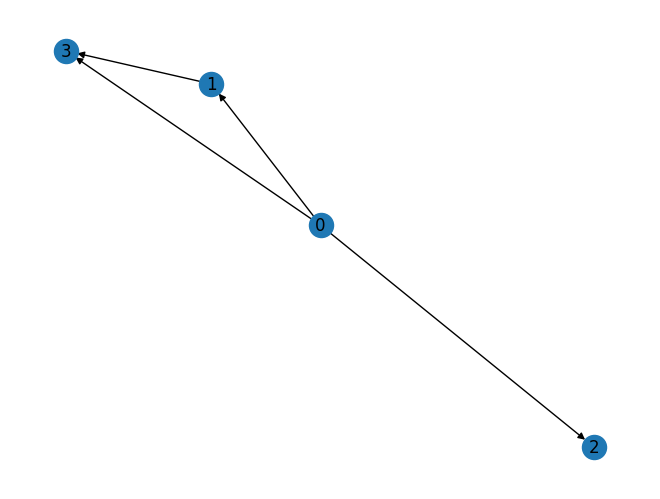

In [ ]:

# convierte de DGL graph → NetworkX graph
nx_g = g.to_networkx()

nx.draw(nx_g, with_labels=True)
plt.show()

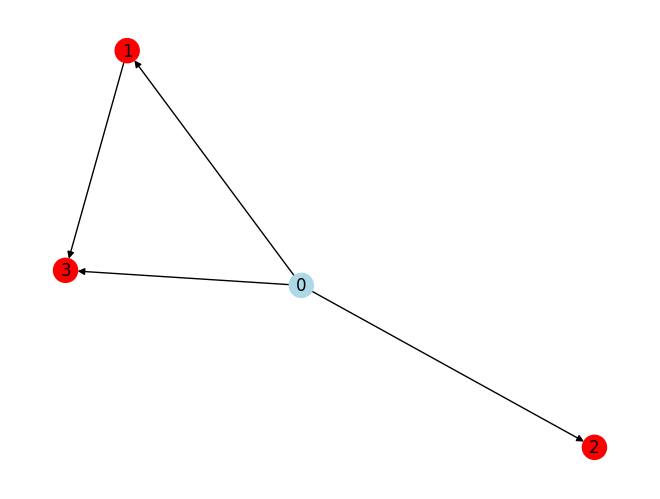

In [59]:
# Colocar un color a los vezinhos de un nodo
neighbors = g.successors(0) # se armacena os vizinhos de 0

node_colors = []

for node in nx_g.nodes():
    if node in neighbors.tolist():
        node_colors.append('red')
    else:
        node_colors.append('lightblue')

nx.draw(nx_g, with_labels=True, node_color=node_colors)
plt.show()